# Task 3 – Predictive Analytics: Sales Forecasting

**Thiranex Data Analytics Internship · Aditya Chauhan**

**Goal:** forecast monthly sales for the next 12 months (Nov 2026 – Oct 2027) so the business can plan inventory, staffing and campaigns.

**Approach**
1. Clean the order-level data and aggregate it into a monthly time series
2. Explore the **trend** and **seasonality**
3. Hold out the last 12 months as a test set and compare three models:
   - **Seasonal Naive** (baseline: "this month = same month last year")
   - **Linear Regression** with a trend term plus month-of-year dummies
   - **Holt-Winters Exponential Smoothing** (multiplicative seasonality)
4. Evaluate with **MAE, RMSE and MAPE**, pick the best model, retrain it on all data and forecast the next 12 months with an uncertainty range

**Dataset:** `retail_sales_data.csv` (same data as Tasks 1 and 2).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from scipy.optimize import minimize

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)
lakh = mtick.FuncFormatter(lambda x, _: f"₹{x/1e5:.0f}L")   # axis labels in lakhs

## 1. Load and clean the data

In [2]:
df = pd.read_csv("../retail_sales_data.csv", parse_dates=["Order Date"])
print(f"{len(df):,} order lines | {df['Order Date'].min().date()} to {df['Order Date'].max().date()}")
print("Missing values:", int(df.isna().sum().sum()), "| Duplicates:", int(df.duplicated().sum()),
      "| Non-positive sales:", int((df["Sales"] <= 0).sum()))

5,947 order lines | 2023-01-01 to 2026-10-31
Missing values: 0 | Duplicates: 0 | Non-positive sales: 0


In [3]:
# Aggregate to monthly totals ("MS" = month start)
monthly = df.set_index("Order Date").resample("MS").agg(Sales=("Sales", "sum"), Orders=("Order ID", "nunique"))

# Check for gaps in the time series
full_range = pd.date_range(monthly.index.min(), monthly.index.max(), freq="MS")
print("Months in data:", len(monthly), "| Missing months:", len(full_range.difference(monthly.index)))

# Check for unusual months using a z-score on the month-over-month % change
pct = monthly["Sales"].pct_change()
z = (pct - pct.mean()) / pct.std()
print("Months with |z| > 3 (possible outliers):", int((z.abs() > 3).sum()))
monthly.tail()

Months in data: 46 | Missing months: 0
Months with |z| > 3 (possible outliers): 0


,Sales,Orders
Order Date,,
2026-06-01,"945,885.80",152
2026-07-01,"914,908.00",145
2026-08-01,"916,590.65",158
2026-09-01,"1,004,840.25",191
2026-10-01,"1,314,992.20",226


The monthly series is **complete** (46 months, no gaps) and has **no extreme outliers**. The last month in the data (Oct 2026) is a full month, so it can be used as-is.

## 2. Explore trend and seasonality

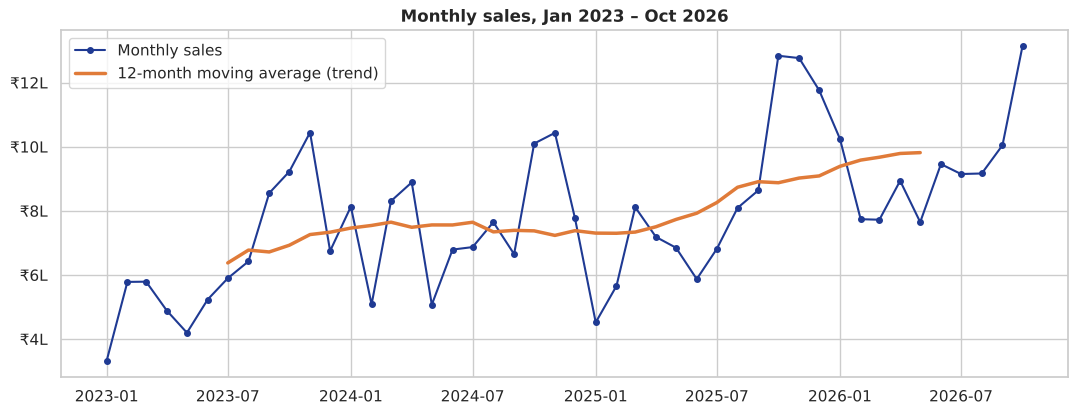

In [4]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(monthly.index, monthly["Sales"], marker="o", ms=4, color="#1F3A93", label="Monthly sales")
ax.plot(monthly.index, monthly["Sales"].rolling(12, center=True).mean(), color="#E07B39", lw=2.5, label="12-month moving average (trend)")
ax.yaxis.set_major_formatter(lakh); ax.set_title("Monthly sales, Jan 2023 – Oct 2026", fontweight="bold"); ax.legend()
plt.show()

Jan   0.93
Feb   0.75
Mar   0.99
Apr   1.01
May   0.77
Jun   0.81
Jul   0.88
Aug   0.96
Sep   1.04
Oct   1.37
Nov   1.42
Dec   1.08


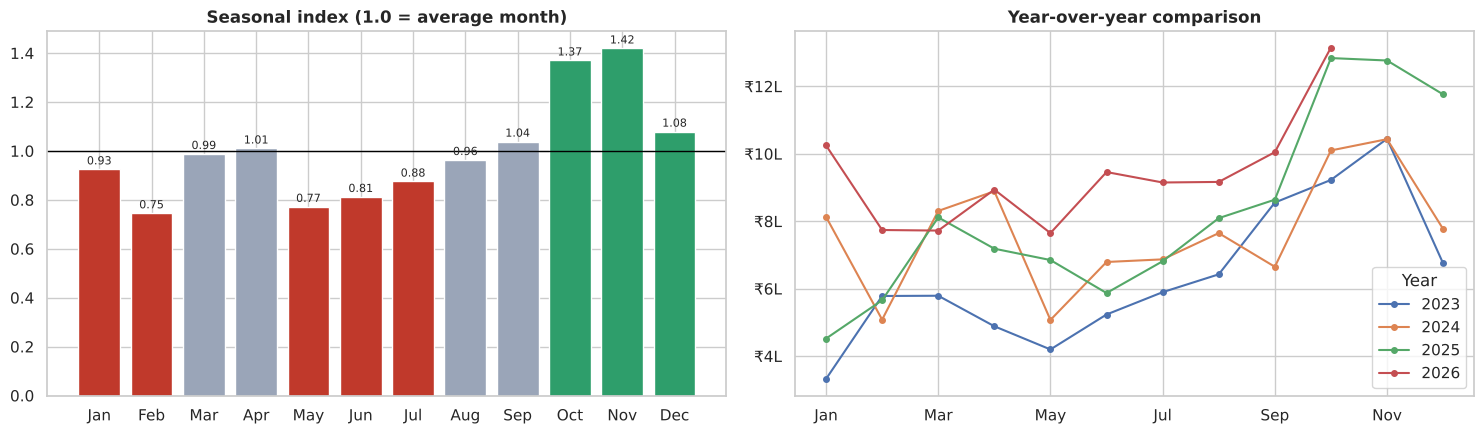

In [5]:
# Seasonal index = how each calendar month compares with its surrounding 12-month average
s = monthly["Sales"]
trend = s.rolling(12, center=True).mean()
seasonal_index = (s / trend).groupby(s.index.month).mean()
seasonal_index = seasonal_index / seasonal_index.mean()          # normalise so the average month = 1.0
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
colors = ["#2E9E6B" if v > 1.05 else ("#C0392B" if v < 0.95 else "#9AA5B8") for v in seasonal_index]
axes[0].bar(month_names, seasonal_index.values, color=colors); axes[0].axhline(1, color="black", lw=1)
axes[0].set_title("Seasonal index (1.0 = average month)", fontweight="bold")
for i, v in enumerate(seasonal_index.values): axes[0].text(i, v + .02, f"{v:.2f}", ha="center", fontsize=8)

yoy = s.to_frame().assign(Year=s.index.year, Month=s.index.month).pivot(index="Month", columns="Year", values="Sales")
yoy.index = month_names
yoy.plot(ax=axes[1], marker="o", ms=4); axes[1].yaxis.set_major_formatter(lakh)
axes[1].set_title("Year-over-year comparison", fontweight="bold")
plt.tight_layout(); plt.show()

print(seasonal_index.set_axis(month_names).round(2).to_string())

**Observations**
- There is a clear **upward trend**: every year sells more than the previous one.
- **Strong, repeating yearly seasonality**: **October and November** (festive season) run about **40% above an average month**, while **February and May** are the weakest, about 25% below average.
- The seasonal swings grow as sales grow, which suggests a **multiplicative** seasonal pattern. This is why Holt-Winters is used with multiplicative seasonality.

Any good model needs to capture both the trend and the 12-month seasonality.

## 3. Train / test split

For time series, the split must respect time order (no random shuffling). I train on **Jan 2023 – Oct 2025** (34 months) and test on the most recent **12 months, Nov 2025 – Oct 2026**, which covers one full seasonal cycle.

In [6]:
y = monthly["Sales"]
H = 12
train, test = y[:-H], y[-H:]
print(f"Train: {train.index[0]:%b %Y} – {train.index[-1]:%b %Y} ({len(train)} months)")
print(f"Test:  {test.index[0]:%b %Y} – {test.index[-1]:%b %Y} ({len(test)} months)")

def evaluate(actual, pred):
    return {"MAE": mean_absolute_error(actual, pred),
            "RMSE": np.sqrt(mean_squared_error(actual, pred)),
            "MAPE (%)": mean_absolute_percentage_error(actual, pred) * 100}
results, preds = {}, {}

Train: Jan 2023 – Oct 2025 (34 months)
Test:  Nov 2025 – Oct 2026 (12 months)


## 4. Models

### 4.1 Baseline – Seasonal Naive
The forecast for each month is simply the value from the same month last year. Any useful model must beat this.

In [7]:
preds["Seasonal Naive"] = pd.Series(train[-12:].values, index=test.index)
results["Seasonal Naive"] = evaluate(test, preds["Seasonal Naive"])
results["Seasonal Naive"]

{'MAE': 214976.50833333333, 'RMSE': np.float64(264508.549882277), 'MAPE (%)': 21.809317576212862}

### 4.2 Linear Regression (trend + seasonality)
Features: a **time index** (captures the trend) and **11 month dummy variables** (capture seasonality; January is the reference month).
This shows that a regression model can forecast a time series once the right features are engineered.

In [8]:
def make_features(index, start_t):
    X = pd.DataFrame({"t": np.arange(start_t, start_t + len(index))}, index=index)
    month_dummies = pd.get_dummies(index.month, prefix="m", drop_first=True).astype(int)
    month_dummies.index = index
    return X.join(month_dummies.reindex(columns=[f"m_{k}" for k in range(2, 13)], fill_value=0))

X_train, X_test = make_features(train.index, 0), make_features(test.index, len(train))
lr = LinearRegression().fit(X_train, train)
preds["Linear Regression"] = pd.Series(lr.predict(X_test), index=test.index)
results["Linear Regression"] = evaluate(test, preds["Linear Regression"])

print(f"Trend: sales grow by about ₹{lr.coef_[0]:,.0f} per month on top of the seasonal pattern")
results["Linear Regression"]

Trend: sales grow by about ₹6,258 per month on top of the seasonal pattern


{'MAE': 133731.56309523658, 'RMSE': np.float64(167818.31777372127), 'MAPE (%)': 13.391894864828114}

### 4.3 Holt-Winters Exponential Smoothing
Holt-Winters keeps three running estimates and updates them each month:
- **Level** (L): the current baseline, smoothed with α
- **Trend** (T): the monthly growth, smoothed with β
- **Seasonality** (S): one factor per calendar month, smoothed with γ

Forecast for *h* months ahead = (L + h·T) × S for that month.
The function is written in plain NumPy, and α, β, γ are chosen by **minimising the training error with `scipy.optimize`**. This is the same idea `statsmodels.ExponentialSmoothing` uses internally.

In [9]:
def holt_winters(series, alpha, beta, gamma, horizon=0, m=12):
    y = np.asarray(series, dtype=float)
    level = y[:m].mean()                                   # initial level = first-year average
    trend = (y[m:2*m].mean() - y[:m].mean()) / m           # initial trend = avg monthly change between year 1 and 2
    season = list(y[:m] / level)                           # initial seasonal factors from year 1
    fitted = []
    for t in range(len(y)):
        s = season[t]
        fitted.append((level + trend) * s)
        prev_level = level
        level = alpha * (y[t] / s) + (1 - alpha) * (level + trend)
        trend = beta * (level - prev_level) + (1 - beta) * trend
        season.append(gamma * (y[t] / level) + (1 - gamma) * s)
    forecast = [(level + h * trend) * season[len(y) + (h - 1) % m] for h in range(1, horizon + 1)]
    return np.array(fitted), np.array(forecast)

def fit_holt_winters(series):
    y = np.asarray(series, dtype=float)
    sse = lambda p: ((y[12:] - holt_winters(y, *p)[0][12:]) ** 2).sum()   # skip the first year (used for initialisation)
    best = minimize(sse, x0=[0.3, 0.05, 0.2], bounds=[(0, 1)] * 3, method="L-BFGS-B")
    return best.x

alpha, beta, gamma = fit_holt_winters(train)
print(f"Optimised parameters: alpha={alpha:.3f}, beta={beta:.3f}, gamma={gamma:.3f}")
_, hw_fc = holt_winters(train, alpha, beta, gamma, horizon=H)
preds["Holt-Winters"] = pd.Series(hw_fc, index=test.index)
results["Holt-Winters"] = evaluate(test, preds["Holt-Winters"])
results["Holt-Winters"]

Optimised parameters: alpha=0.279, beta=0.000, gamma=0.610


{'MAE': 134765.4054207887, 'RMSE': np.float64(171854.2675686067), 'MAPE (%)': 13.851854509398107}

## 5. Model evaluation

In [10]:
res = pd.DataFrame(results).T
res["Improvement vs baseline (MAPE)"] = (1 - res["MAPE (%)"] / res.loc["Seasonal Naive", "MAPE (%)"]) * 100
best_model = res["MAPE (%)"].idxmin()
print("Best model (lowest MAPE):", best_model)
res.round(2)

Best model (lowest MAPE): Linear Regression


,MAE,RMSE,MAPE (%),Improvement vs baseline (MAPE)
Seasonal Naive,"214,976.51","264,508.55",21.81,0.00
Linear Regression,"133,731.56","167,818.32",13.39,38.60
Holt-Winters,"134,765.41","171,854.27",13.85,36.49


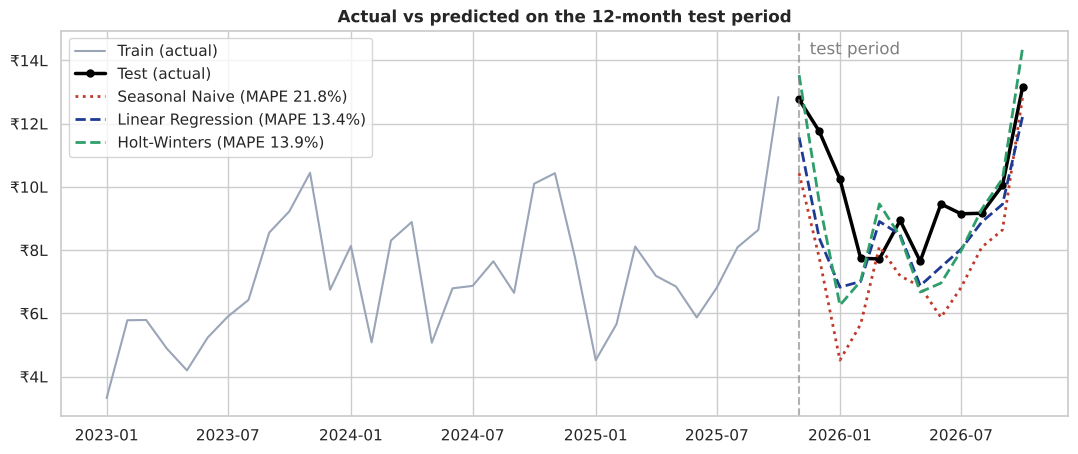

In [11]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(train.index, train, color="#9AA5B8", label="Train (actual)")
ax.plot(test.index, test, color="black", lw=2.5, marker="o", ms=5, label="Test (actual)")
style = {"Seasonal Naive": ("#C0392B", ":"), "Linear Regression": ("#1F3A93", "--"), "Holt-Winters": ("#2E9E6B", "--")}
for name, p in preds.items():
    ax.plot(p.index, p, color=style[name][0], ls=style[name][1], lw=2, label=f"{name} (MAPE {results[name]['MAPE (%)']:.1f}%)")
ax.axvline(test.index[0], color="grey", ls="--", alpha=.6); ax.text(test.index[0], ax.get_ylim()[1]*.95, "  test period", color="grey")
ax.yaxis.set_major_formatter(lakh); ax.legend(loc="upper left"); ax.set_title("Actual vs predicted on the 12-month test period", fontweight="bold")
plt.show()

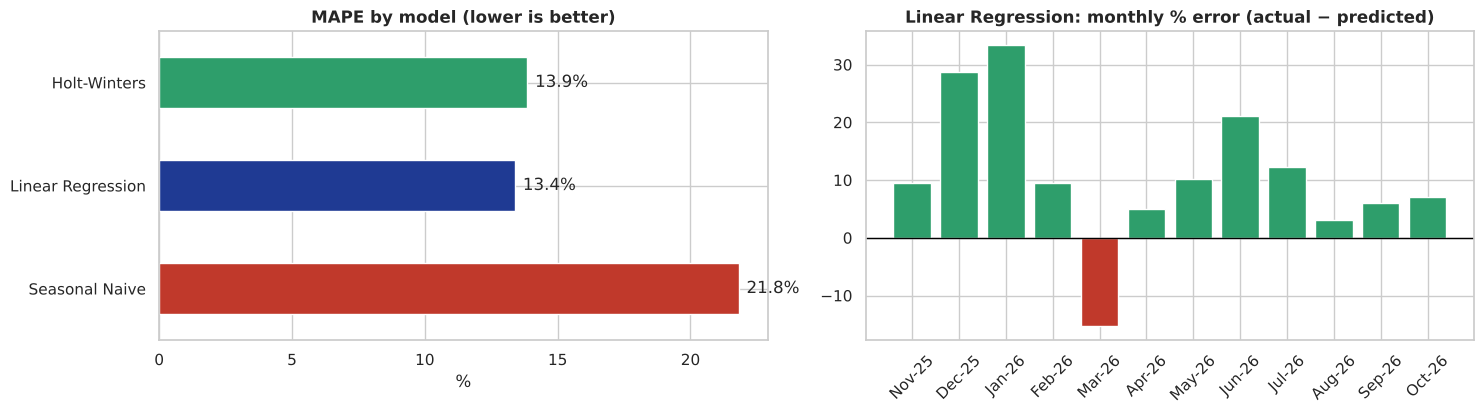

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
res["MAPE (%)"].plot(kind="barh", ax=axes[0], color=[style[n][0] for n in res.index])
axes[0].set_title("MAPE by model (lower is better)", fontweight="bold"); axes[0].set_xlabel("%")
for i, v in enumerate(res["MAPE (%)"]): axes[0].text(v + .3, i, f"{v:.1f}%", va="center")

err = (test - preds[best_model]) / test * 100
axes[1].bar(err.index.strftime("%b-%y"), err.values, color=["#2E9E6B" if e >= 0 else "#C0392B" for e in err])
axes[1].axhline(0, color="black", lw=1); axes[1].set_title(f"{best_model}: monthly % error (actual − predicted)", fontweight="bold")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## 6. Final forecast: Nov 2026 – Oct 2027

The best model is **retrained on all 46 months**, so it learns from the most recent data, and then forecasts the next 12 months.
The **approximate 95% range** is the forecast ± 1.96 × the model's RMSE on the test set. It gives an honest sense of how far off the forecast could be.

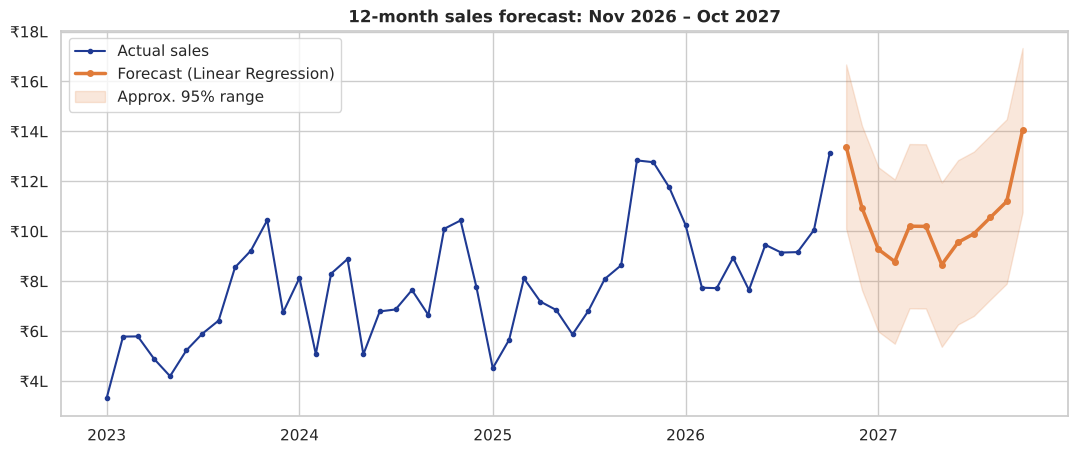

,Forecast,Lower_95,Upper_95
MonthName,,,
Nov 2026,"1,339,205.00","1,010,281.00","1,668,129.00"
Dec 2026,"1,093,648.00","764,725.00","1,422,572.00"
Jan 2027,"927,748.00","598,824.00","1,256,672.00"
Feb 2027,"878,733.00","549,809.00","1,207,657.00"
Mar 2027,"1,020,504.00","691,580.00","1,349,428.00"
Apr 2027,"1,019,604.00","690,680.00","1,348,528.00"
May 2027,"866,386.00","537,462.00","1,195,310.00"
Jun 2027,"956,060.00","627,136.00","1,284,984.00"
Jul 2027,"990,394.00","661,470.00","1,319,317.00"


In [13]:
future_index = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(1), periods=H, freq="MS")
if best_model == "Linear Regression":
    final_model = LinearRegression().fit(make_features(y.index, 0), y)
    forecast = final_model.predict(make_features(future_index, len(y)))
elif best_model == "Holt-Winters":
    _, forecast = holt_winters(y, *fit_holt_winters(y), horizon=H)
else:
    forecast = y[-12:].values

band = 1.96 * results[best_model]["RMSE"]
fc = pd.DataFrame({"Forecast": forecast, "Lower_95": forecast - band, "Upper_95": forecast + band}, index=future_index)
fc.index.name = "Month"

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(y.index, y, color="#1F3A93", marker="o", ms=3, label="Actual sales")
ax.plot(fc.index, fc["Forecast"], color="#E07B39", marker="o", ms=4, lw=2.5, label=f"Forecast ({best_model})")
ax.fill_between(fc.index, fc["Lower_95"], fc["Upper_95"], color="#E07B39", alpha=.18, label="Approx. 95% range")
ax.yaxis.set_major_formatter(lakh); ax.legend(loc="upper left")
ax.set_title("12-month sales forecast: Nov 2026 – Oct 2027", fontweight="bold")
plt.show()

fc.assign(MonthName=fc.index.strftime("%b %Y")).set_index("MonthName").round(0)

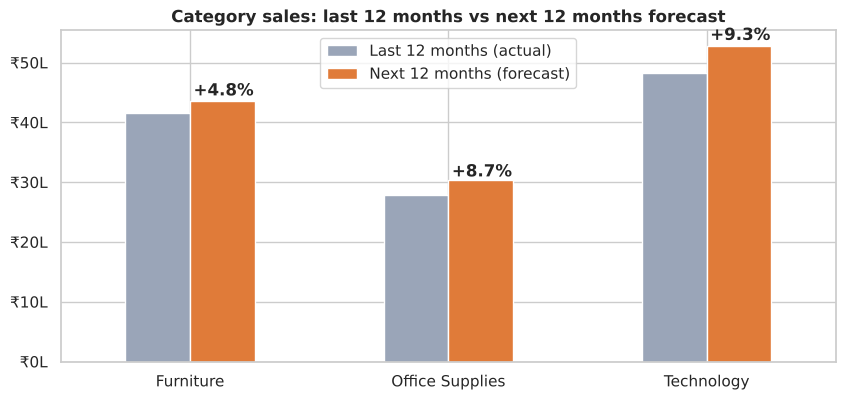

,Last 12 months (actual),Next 12 months (forecast),Expected growth (%)
Furniture,"4,164,022.40","4,363,342.70",4.80
Office Supplies,"2,793,177.90","3,035,343.20",8.70
Technology,"4,822,574.70","5,273,481.80",9.30


In [14]:
# Forecast by category: same model applied to each category's own monthly series
cat_monthly = df.pivot_table(index=pd.Grouper(key="Order Date", freq="MS"), columns="Category", values="Sales", aggfunc="sum")
cat_fc = {}
for cat in cat_monthly.columns:
    s_cat = cat_monthly[cat]
    if best_model == "Holt-Winters":
        _, f_cat = holt_winters(s_cat, *fit_holt_winters(s_cat), horizon=H)
    else:
        f_cat = LinearRegression().fit(make_features(s_cat.index, 0), s_cat).predict(make_features(future_index, len(s_cat)))
    cat_fc[cat] = {"Last 12 months (actual)": s_cat[-12:].sum(), "Next 12 months (forecast)": f_cat.sum()}
cat_fc = pd.DataFrame(cat_fc).T
cat_fc["Expected growth (%)"] = (cat_fc.iloc[:, 1] / cat_fc.iloc[:, 0] - 1) * 100

ax = cat_fc.iloc[:, :2].plot(kind="bar", figsize=(10, 4.3), color=["#9AA5B8", "#E07B39"], rot=0)
ax.yaxis.set_major_formatter(lakh); ax.set_title("Category sales: last 12 months vs next 12 months forecast", fontweight="bold"); ax.set_xlabel("")
for i, g in enumerate(cat_fc["Expected growth (%)"]):
    ax.text(i + .13, cat_fc.iloc[i, 1] * 1.02, f"{g:+.1f}%", ha="center", fontweight="bold")
plt.show()
cat_fc.round(1)

In [15]:
# Key numbers for the summary
last12, next12 = y[-12:].sum(), fc["Forecast"].sum()
peak = fc["Forecast"].idxmax(); low = fc["Forecast"].idxmin()
festive = fc.loc[fc.index.month.isin([10, 11]), "Forecast"].sum() / next12 * 100
print(f"Best model: {best_model} | test MAPE {results[best_model]['MAPE (%)']:.1f}% vs baseline {results['Seasonal Naive']['MAPE (%)']:.1f}%")
print(f"Last 12 months actual: ₹{last12:,.0f}")
print(f"Next 12 months forecast: ₹{next12:,.0f}  ({(next12/last12-1)*100:+.1f}%)")
print(f"Peak month: {peak:%b %Y} (₹{fc.loc[peak,'Forecast']:,.0f}) | Lowest: {low:%b %Y} (₹{fc.loc[low,'Forecast']:,.0f})")
print(f"Oct + Nov share of next year's forecast: {festive:.1f}%")

Best model: Linear Regression | test MAPE 13.4% vs baseline 21.8%
Last 12 months actual: ₹11,779,775
Next 12 months forecast: ₹12,672,168  (+7.6%)
Peak month: Oct 2027 (₹1,404,987) | Lowest: May 2027 (₹866,386)
Oct + Nov share of next year's forecast: 21.7%


## 7. Key insights

1. **The forecasting models clearly beat the baseline.** Linear Regression (trend + month dummies) had the lowest error, a **13.4% MAPE versus 21.8% for the seasonal naive baseline (39% better)**. Holt-Winters was almost as good (13.9%). Two different methods reaching similar accuracy makes the forecast more trustworthy.
2. **Sales should keep growing, but more slowly.** The next 12 months (Nov 2026 – Oct 2027) are forecast at **₹1.27 Cr, about 7.6% above the last 12 months (₹1.18 Cr)**. That's slower than the ~20% growth seen in 2024.
3. **The festive season drives the year.** October and November are the peak months: **Oct 2027 is forecast at ~₹14.0 L and Nov 2026 at ~₹13.4 L**. The quietest months are **Feb and May 2027 (~₹8.7–8.8 L)**.
4. **Technology leads category growth** (+9.3%), followed by Office Supplies (+8.7%). Furniture grows slowest (+4.8%).
5. **Plan with ranges, not single numbers.** The approximate 95% range is about **±₹3.3 L per month**, so a monthly forecast of ₹10 L realistically means ₹6.7–13.3 L.

## 8. Recommendations
- **Build inventory and plan staffing by September** so the business is ready for the Oct–Nov peak, especially Technology products.
- **Use the slow months (Feb, May) for promotions** or clearance sales to smooth out demand.
- **Set targets at roughly +7–8% for next year**, using the forecast range for best- and worst-case planning.
- **Re-run the forecast every month** as new data comes in. The model takes seconds to retrain.

## 9. Limitations and next steps
- Only **46 months** of history (fewer than four seasonal cycles), and accuracy was checked on a **single 12-month holdout**. Rolling-origin cross-validation would give a more reliable error estimate.
- The models only use past sales. They don't account for **external factors** like Diwali falling on different dates each year, marketing campaigns or the economy.
- With more data, models like **SARIMA, Prophet or gradient boosting with lag features** could be compared against these.

In [16]:
fc.round(2).to_csv("sales_forecast_next_12_months.csv")
print("Saved sales_forecast_next_12_months.csv")

Saved sales_forecast_next_12_months.csv
